# Entraînement et test de différents modèles

### Préparation des données :

##### Import des librairies :

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, AdaBoostClassifier
from scipy.stats import randint, uniform, loguniform
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

##### Chargement des données d'entrainement et de test nettoyés :

In [2]:
data_train = pd.read_csv("data_train_clean.csv")
data_test = pd.read_csv("data_test_clean.csv")

data_train = data_train.drop(columns=["Unnamed: 0"])
data_test = data_test.drop(columns=["Unnamed: 0"])

##### On sépare les covariables de la variable cible dans les données d'entraînement :

In [3]:
X_train = data_train.drop(columns=["accepted", "id"])
Y_train = data_train["accepted"]
X_test = data_test.drop(columns=["id"])

##### On normalise :

In [4]:
scaler = StandardScaler()
X_train_normed = scaler.fit_transform(X_train)
X_test_normed = scaler.transform(X_test)

## Modèles :

### Arbre de décision : 

##### Entraînement :

`max_depth` est un hyperparamètre qui fixe la profondeur maximale de l’arbre, c’est-à-dire le nombre maximal de questions successives qu’on peut poser avant d’arriver à une prédiction. Pour le choisir, on peut utiliser une courbe de validation. Pour chaque valeur de `max_depth`, on veut savoir comment l’arbre se comporte sur des données qu’il n’a pas vues pendant son entraînement. `validation_curve` automatise cela avec une validation croisée, et renvoie les scores AUC pour qu'on puisse les tracer. On veut évidemment obtenir la plus grande AUC.

Il n'y a pas besoin d'utiliser `X_train_normed` pour les arbres de décision.

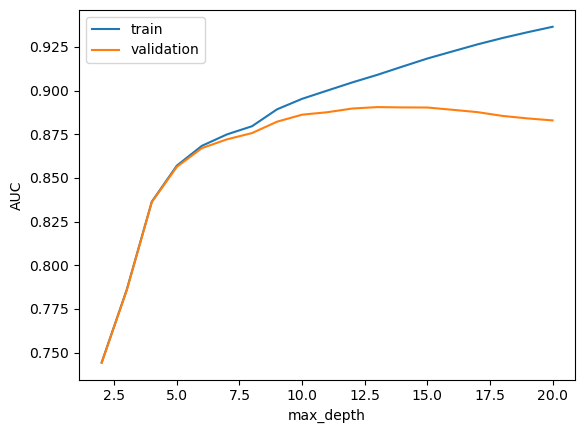

In [5]:
depths = np.arange(2, 21)

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=50, random_state=42),
    X_train, Y_train,
    param_name="max_depth", param_range=depths,
    cv=5, scoring="roc_auc", n_jobs=-1,
)

plt.plot(depths, train_scores.mean(axis=1), label="train")
plt.plot(depths, val_scores.mean(axis=1), label="validation")
plt.xlabel("max_depth")
plt.ylabel("AUC")
plt.legend()
plt.show()

In [6]:
val_mean = val_scores.mean(axis=1)

i_max = val_mean.argmax()          # indice du maximum

x_max = depths[i_max]              # abscisse (max_depth)
y_max = val_mean[i_max]            # valeur max (AUC)

print(f"Maximum : AUC = {y_max:.4f} pour max_depth = {x_max}")

Maximum : AUC = 0.8905 pour max_depth = 13


In [7]:
model_tree = DecisionTreeClassifier(max_depth=13, random_state=42) 
model_tree.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=13, random_state=42)

##### Prédictions :

In [8]:
# Probabilité de la classe 1 (accepté)
y_proba = model_tree.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "id": data_test["id"],
    "accepted": y_proba
})

submission.to_csv("submission_decision_tree_clean.csv", index=False)

Sur kaggle, on obtient un score de 0.86618

### Gradient boosting :

##### Entraînement :

Pas besoin de normaliser les données d'entraînement.

In [9]:
model_gdt_boost = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=1000,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=50,
    scoring="roc_auc",
    random_state=42,
)
model_gdt_boost.fit(X_train, Y_train)
print("Nombre d'arbres retenu :", model_gdt_boost.n_iter_)

C:\Users\slese\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\slese\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\slese\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\slese\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^

Nombre d'arbres retenu : 272


##### Prédictions :

In [10]:
# Probabilité de la classe 1 (accepté)
y_proba = model_gdt_boost.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "id": data_test["id"],
    "accepted": y_proba
})

submission.to_csv("submission_gradient_boosting_try1_clean.csv", index=False)

Sur kaggle, on obtient un score de 0.91570